<a href="https://colab.research.google.com/github/MelisaYasak/transformer_arch/blob/main/sherlockGPT_train_explain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%cd /content/drive/MyDrive/transformers

/content/drive/MyDrive/transformers


Transformer metinleri doğrudan değil, sayısal token ID'leri üzerinden işler. Bu da veriyi token'la bölmemiz gerektiğini gösterir.

Çeşitli token üretme metotları vardır. Biz küçük ve basit bir model eğiteceğimizden ve amacımız eğitimin nasıl olduğunu öğrenmek olduğundan **character-level** tokenizer kullanacağız.

#### Karşılaştırma

1. Bağlam uzunluğu
Context length = 8 olduğunu düşünelim.
- Character-level: Model yalnızca Sherlock gibi 8 karakter görebilir.
- Word-level: Model Sherlock opened the door and looked at Watson gibi 8 kelime görebilir.
Dolayısıyla aynı token sınırında word-level model daha geniş bir dilsel context görebilir.

2. Bir başka önemli fark: Öğrenme yükü
Character-level modelin yalnızca kelimeler arasındaki ilişkileri değil, kelimelerin nasıl yazıldığını da öğrenmesi gerekir.

Örneğin detective kelimesini üretebilmek için sırayla şu karakterleri tahmin etmesi gerekir:

d → e → t → e → c → t → i → v → e

Word-level model ise sözlüğünde detective varsa bu kelimeyi tek bir token olarak üretebilir.

Bu nedenle karakter seviyesinde modelin anlamlı, uzun metinler üretmesi daha fazla ardışık tahmin gerektirebilir.

# 01_Tokenizer Mantığı

In [4]:
text = "Sherlock Holmes"

In [5]:
chars = sorted(set(text))

In [9]:
# string to integer # enumerate() listedeki her elemanın indeksini ve kendisini birlikte verir. Bunu da stoi adında bir dictte tutuyoruz.
stoi = {ch: i for i, ch in enumerate(chars)}
# integer to string
itos = {i: ch for ch, i in stoi.items()}

In [10]:
# encode s ile gelen bir textin stoi[c] ile karakterlerin sayısal IDlerini buluyor ve liste olarak döndürüyor.
encode = lambda s: [stoi[c] for c in s]

#decode lambda func ile encode edilmiş sayısal olan arrayin kelime karşılığını bulup bunu bir metin olarak return ediyor.
decode = lambda ids: "".join(itos[i] for i in ids)

In [8]:
print("Vocabulary:", chars)
print("Vocabulary size:", len(chars))
print("Encoded:", encode(text))
print("Decoded:", decode(encode(text)))

Vocabulary: [' ', 'H', 'S', 'c', 'e', 'h', 'k', 'l', 'm', 'o', 'r', 's']
Vocabulary size: 12
Encoded: [2, 5, 4, 10, 7, 9, 3, 6, 0, 1, 9, 7, 8, 4, 11]
Decoded: Sherlock Holmes


# 02_INPUT

In [11]:
import torch

In [12]:
text = 'SHERLOCK'

In [13]:
chars = sorted(set(text))

In [14]:
stoi = {ch: i for i, ch in enumerate(chars)}

In [18]:
# Karakter ID'lerini bir PyTorch tensor'üne dönüştürüyoruz.
data = torch.tensor(
    [stoi[c] for c in text],
    dtype=torch.long
)

In [20]:
# Her eğitim dizisindeki bağlam uzunluğu
block_size = 4

In [21]:
# Inputumuz burada datamızda bağlam boyumuz kadar input alıyoruz.
x = data[:block_size]

# Aynı diziyi bir kaydırarak target belirliyoruz
y = data[1:block_size + 1]

yani bu ne demek?

text'imiz SHERLOCK

Biz karakter tokenizer kullandık ve bağlam penceremiz 4 karakter.

eğer direkt metni alsaydık
- inputumuz **[S H E R]** olacak
- targetımız **[H E R L]** olacaktı.

Çünkü yeni harfin L olduğunu anlayabilmesi için bağlama yani bağlam kadar uzun olan eski harflere ihtiyacı var

In [23]:
print("Input:", x)
print("Target:", y)

Input: tensor([7, 2, 1, 6])
Target: tensor([2, 1, 6, 4])


# 03_Logits, Softmax ve Loss

## Modelin tahmin edeceği karaktere verdiği skor bir nevi ağırlık: LOGIT

In [24]:
import torch
import torch.nn.functional as F

In [25]:
logits = torch.tensor([2.0,1.0,0.0])

## Tüm logit'leri birlikte değerlendirerek olasılık dağılımına dönüştüren foksiyon: SOFTMAX

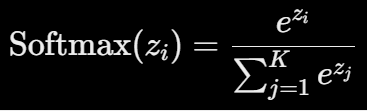



Dipnot: Neden Euler sayısını kullanıyoruz? Çünkü e^2 türevi de kendisidir.

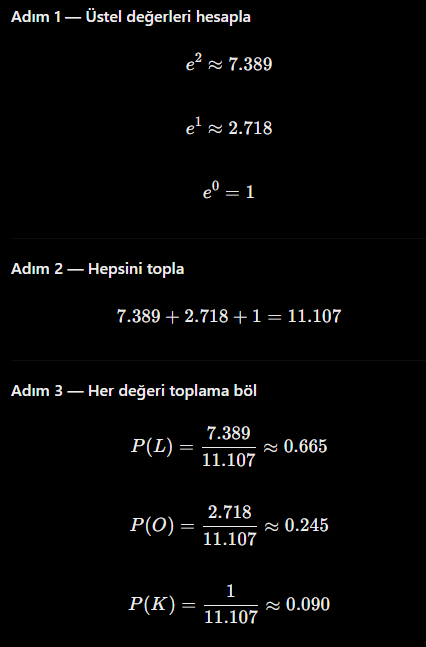

## koda bakalım

In [26]:
# dim=0 ise tek boyutlu tensor'ümüzde hangi eksen boyunca softmax uygulanacağını söylüyor.
probs = F.softmax(logits, dim=0)

In [27]:
print("Logits:", logits)
print("Probabilities:", probs)
print("Total:", probs.sum())

Logits: tensor([2., 1., 0.])
Probabilities: tensor([0.6652, 0.2447, 0.0900])
Total: tensor(1.)


buradaki probları şöyle yazabiliriz

P(L)=0.665, P(O)=0.245, P(K)=0.090


# 04_Cross-Entropy ve Gradient

## Cross Entropy:
Doğru karakterin olasılık değerlerini kullanarak hatayı hesaplar.

**_L = -ln P(karakter)_**


---



Dipnot1: Burada ln, doğal logaritmadır. Softmax'teki \(e\) sayısının ters işlemiyle bağlantılıdır.

Dipnot2: Neden negatif logaritma kullanıyoruz. Çünkü loss ve olasılık değeri ters orantılıdır. Model doğru cevaba sıfıra yakın olasılıkta değer verirse loss büyür.

In [31]:
# doğru olan karakterin indexini aldık.
target = torch.tensor([0])

In [ ]:

loss = F.cross_entropy(
    logits.unsqueeze(0),
    target
)

In [30]:
print("Loss: ", loss.item())

Loss:  0.40760594606399536


## Gradient
Modelin lossunu düşürebilmek için logitlerin bağlı olduğu öğrenilebilir ağırlıkları hangi yönde güncellememiz gerektiğini açıklayan terim

Yani TÜREV

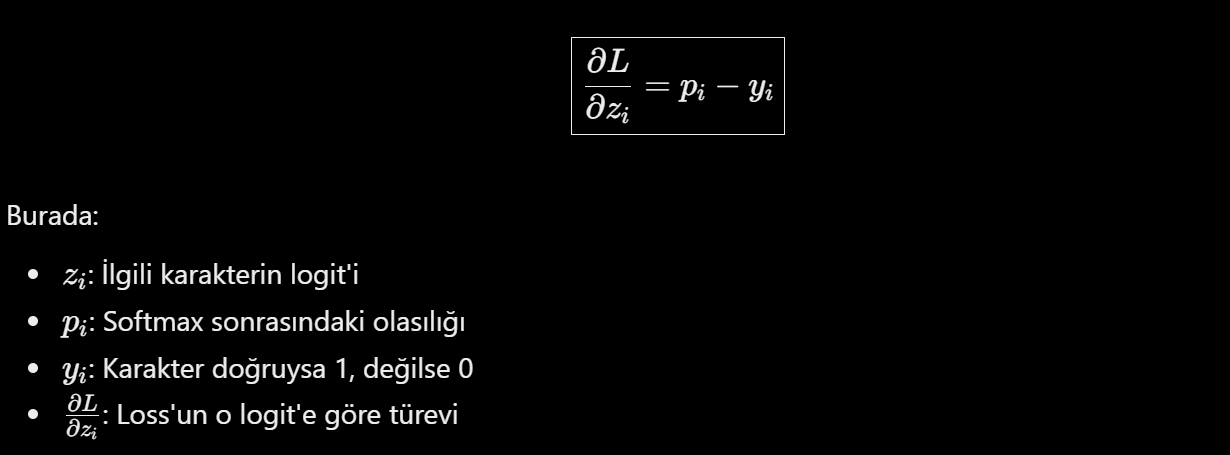

In [32]:
import torch
import torch.nn.functional as F

In [37]:
logits = torch.tensor(
    [[2.0, 1.0, 0.0]],
    requires_grad=True # Hangi tensor üzerinden türev yani gradient hesaplanacak?
    )

In [38]:
target = torch.tensor([0])

In [39]:

print("Logits shape:", logits.shape)
print("Target shape:", target.shape)

Logits shape: torch.Size([1, 3])
Target shape: torch.Size([1])


In [40]:
loss = F.cross_entropy(logits, target)

In [41]:
loss.backward()

In [42]:
print("Loss:", loss.item())

# Modelin bir sonraki stepte ağırlıkları ile ne yapması gerektiğini söylüyor.
# Bizim gerçek y = [1, 0, 0] Çünkü [L, O, K]
print("Gradients:", logits.grad)

# Gradients: tensor([[-0.3348,  0.2447,  0.0900]])
# Output bize şunu söylüyor: sen olasığı 0.6 bulmuştun ama gerçek değer 1 (gradient negatif)
# yani L'yi doğru tahmin edebilmen için L logitisini arttırmalısın
# diğerleri pozitf olduğundan yükseltmelisin

Loss: 0.40760594606399536
Gradients: tensor([[-0.3348,  0.2447,  0.0900]])


Yeni değeri bulabilmek için de


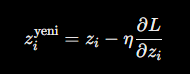

# 05_Model ağırlıkları ve optimizer

In [67]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [68]:
torch.manual_seed(42) # kutsal sayımız :)

In [69]:
x = torch.tensor([[1.0]])
x.shape

torch.Size([1, 1])

In [70]:
target = torch.tensor([0])

In [71]:
# Basit olması açısından lineer kullanacağım.
# z = aW^T + b
model = nn.Linear(1,3)

In [72]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

In [73]:
logits = model(x)

In [74]:
loss = F.cross_entropy(logits, target)

In [75]:
print("Logits:", logits)
print("Loss:", loss.item())


Logits: tensor([[ 1.6831,  0.6109, -0.0325]], grad_fn=<AddmmBackward0>)
Loss: 0.4200838804244995


## Çok Stepli Eğitim

In [76]:
print("Önce: ", model.weight.data)

for step in range(10):
  # Önce bi gradient'ı temizleyelim
  optimizer.zero_grad()

  # random ile oluşturduğumuz ağırlıklarla tahmin ettirelim
  logits = model(x)

  #Tahmin hatasını hesaplayalım
  loss = F.cross_entropy(logits, target)

  #parametrelerin gradientlerini hesaplayalım
  loss.backward()

  # parametreleri güncelleyelim ve başa dönelim
  optimizer.step()

  print(f"Step {step+1}: Loss = {loss.item():.4f}")
print("Sonra: ", model.weight.data)

Önce:  tensor([[ 0.7645],
        [ 0.8300],
        [-0.2343]])
Step 1: Loss = 0.4201
Step 2: Loss = 0.3849
Step 3: Loss = 0.3544
Step 4: Loss = 0.3278
Step 5: Loss = 0.3045
Step 6: Loss = 0.2839
Step 7: Loss = 0.2657
Step 8: Loss = 0.2494
Step 9: Loss = 0.2349
Step 10: Loss = 0.2218
Sonra:  tensor([[ 1.0258],
        [ 0.6629],
        [-0.3284]])
